
# But du laboratoire

L'objectif est d'apprendre à utiliser les modules numpy et matplotlib, pour manipuler des tableaux et afficher des graphiques.

# Travail obligatoire


In [3]:

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
#%matplotlib qt

## Exercice 3 : "Régression polynomiale"

Cet exercice a pour but de découvrir le module `polynomial` de numpy, ainsi que de réaliser des graphiques avec des barres d'erreur.

On vous fournit les listes `L` et `F` qui représentent la longueur d'un ressort et la force qui lui est appliquée, mesurée à l'aide d'un dynamomètre. L'incertitude sur la mesure de la force est de 0.5N, et est représenté par `F_UNCERTAINTY`.

1. Tracer le graphique de la force en fonction de la longueur, avec des barres d'erreurs. Utiliser la fonction `errorbar()` de matplotlib, avec les arguments `capsize` et `mew` pour obtenir la même mise en forme que sur l'exemple.
2. A l'aide du module `polynomial`, calculer et évaluer les régressions du 1er ordre et du 3ème ordre sur la série de mesure :
    * La fonction `polyfit()` permet de trouver les coefficients du modèle
    * `p = Polynomial(coefs)` permet de créer un polynome à partir des coefficients, qui pourra ensuite être évalué à différentes valeurs de `x`
    * Pour tracer la courbe, vous devrez d'abord créer un vecteur `x` allant de 0 à 20 en utilisant `np.linspace()`, puis vous pourrez évaluer votre polynome aux valeurs de `x` en exécutant `y = p(x)`.
3. Calculez l'erreur quadratique moyenne (MSE) pour les 2 types de régression, selon la formule suivante :
    $$MSE = \frac{1}{N} \sum_{i=0}^{N-1} (y_i-\hat{y}_i)^2$$
    * $N$ correspond au nombre d'échantillons mesurés, $y_i$ à la mesure, et $\hat{y}_i$ à la valeur estimée par le modèle
    * Pour calculer la MSE, vous devrez évaluer les 2 types de régression, pour les longueurs correspondant à la mesure. C'est ces valeurs qui vont correspondre à $\hat{y}_i$

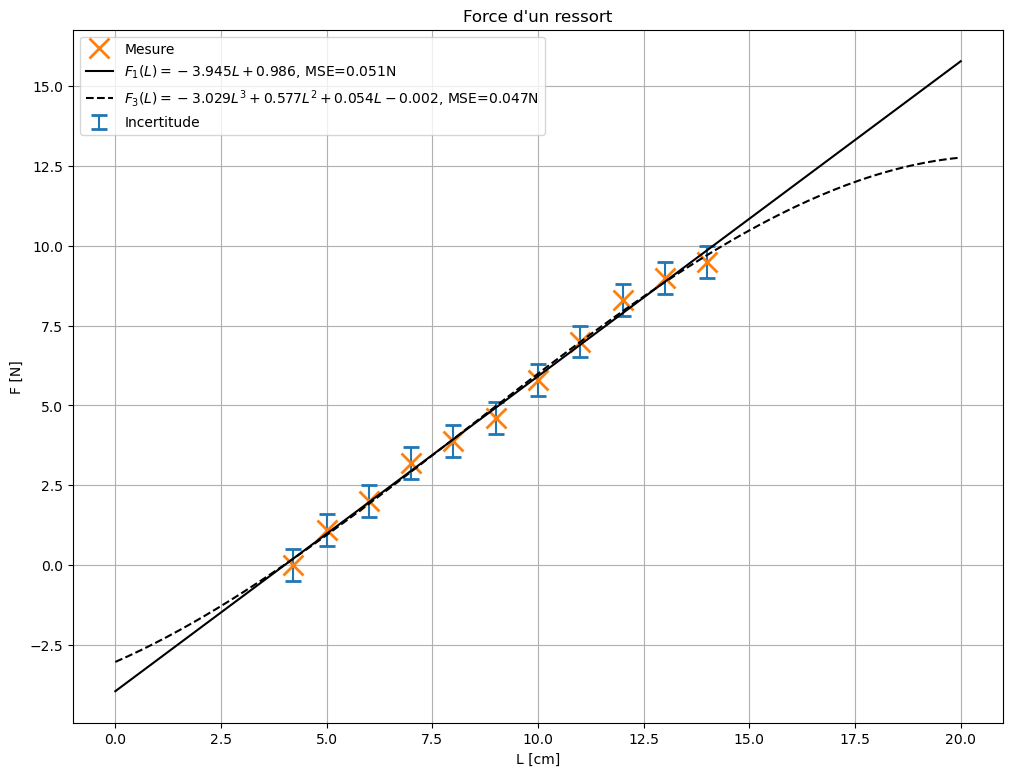

In [4]:
L = [4.2,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0]  # Longueur en cm
F = [0.0,1.1,2.0,3.2,3.9,4.6,5.8,7.0,8.3,9.0,9.5]       # Force en newton
F_UNCERTAINTY = 0.5     # Incertitue sur la force [N]

from numpy.polynomial.polynomial import polyfit
from numpy.polynomial import Polynomial

### Votre code

# Régression : calcul des coefficients
#coef_fit_1 = polyfit(L,F,1)
#p_fit_1 = Polynomial(coef_fit_1)
#coef_fit_3 = polyfit(L,F,3)
#p_fit_3 = Polynomial(coef_fit_3)

p_fit_1 = Polynomial.fit(L,F,1)
p_fit_3 = Polynomial.fit(L,F,3)

# Vecteur x pour la régression
N_X_FIT = 200
x_fit = np.linspace(0,20,N_X_FIT)

# Appliquer la régression
y_fit_1 = p_fit_1(x_fit)
y_fit_3 = p_fit_3(x_fit)

def get_mse(x,y,p):
    """Calcul de l'erreur quadratique moyenne

    Args:
        x (liste ou numpy array): points à calculer, valeurs en x
        y (liste ou numpy array): points à calculer, valeurs en y
        p (Polynomial): polynôme de régression

    Returns:
        float: erreur quadratique moyenne
    """
    y_fit = p(np.asarray(x))            # Appliquer la régression
    return np.sum((y-y_fit)**2)/len(x)  # Evaluer l'erreur

def get_legend_fit(coefs, mse):
    """Fonction retournant le texte mis en forme pour afficher
       la légende des courbes de régressions sur le plot

    Args:
        coefs (liste ou numpy array): coefficients du polynôme de régression
        mse (float): erreur quadratique moyenne

    Returns:
        str: texte mis en forme
    """
    
    degree = len(coefs)-1

    # Conversion des coefficients en un texte exprimant l'équation a0+a1*L+a2*L^2+...
    lgd = '+'.join([f'{coef:.3f} L^{exponent}' for coef,exponent in \
        zip(coefs,reversed(range(degree+1)))])

    # Suppression des termes inutiles / redondants
    lgd = lgd.replace('+-','-').replace(' L^0','').replace('L^1','L')

    # Ajout de la MSE dans le texte
    return f'$F_{degree}(L) = {lgd}$, MSE={mse:.3f}N'

# Calculer MSE et mise en forme du texte de la légende pour les 2 courbes de régressions
str_fit_1 = get_legend_fit(coef_fit_1, get_mse(L,F,p_fit_1))
str_fit_3 = get_legend_fit(coef_fit_3, get_mse(L,F,p_fit_3))


plt.figure(figsize=(12,9))

# Affichage des barres d'erreurs
plt.errorbar(L,F,yerr=F_UNCERTAINTY,capsize=6, mew=2,linestyle='',label='Incertitude')

# Affichage des points de mesure (fait dans une ligne séparée,
# car dans une autre couleur que les barres d'erreur)
plt.plot(L,F,'x',markersize=15,mew=2,label='Mesure')

# Courbes de régression
plt.plot(x_fit, y_fit_1, label=str_fit_1,color='k')
plt.plot(x_fit, y_fit_3, '--', label=str_fit_3,color='k')

plt.xlabel('L [cm]')
plt.ylabel('F [N]')
plt.title('Force d\'un ressort')
plt.legend()
plt.grid()


###

## Exercice 4 : "Détecteur piece"
Le but de cet exercice est de se familiariser avec les images et les matrices en 2D.
Pour ce faire, une image d'une pièce est bruitée et pas centrée. L'objectif est de couper l'image afin de ne garder que la pièce.

1. Lire l'image avec `img = plt.imread('data/coins.bmp')` et afficher l'image avec `plt.imshow()`.
2. Afficher les informations suivante de la matrice `img` :
   - dimensions : `np.shape(img)` 
   - valeur minimum : `np.min()` 
   - valeur maximum : `np.max()`
   - type de la matrice: `type()`
   - type d'une valeur (pixel) : `type(img[0,0])`
3. Binariser l'image. Celà consiste à tester si les pixels sont plus grand qu'un seuil `T` : `img > T`
4. Sommer indépendemment chaque axe de la matrice. Celà correspond à une projection horizontale ou verticale `proj = np.sum(img,axis = ...)`
5. Afficher chaque projection et déterminer le début et la fin de la pièce en utilisant pour chaque projection `np.where(proj > ...)`
6. Couper l'image en utilisant les débuts et fins obtenus.

In [11]:
# export data (not shared)
from skimage import data, util, io
from skimage.util import img_as_ubyte

image = img_as_ubyte(data.coins()[150:230, 10:70])
image = img_as_ubyte(util.random_noise(image, mode='s&p', amount=0.05))

io.imsave('./data/coins.bmp', image)

image = []

matrice dim :  (80, 60)
matrix min : 0
matrix max : 255
type matrice <class 'numpy.ndarray'>
type pixel <class 'numpy.uint8'>


Text(0.5, 1.0, 'Projection V')

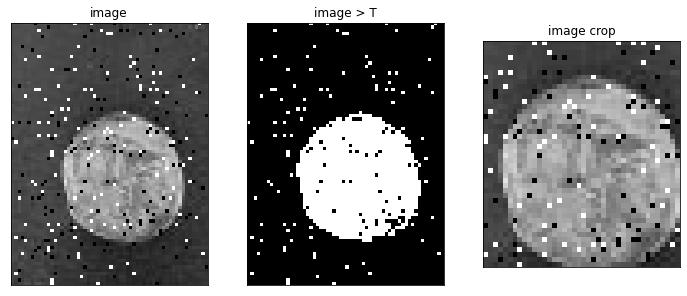

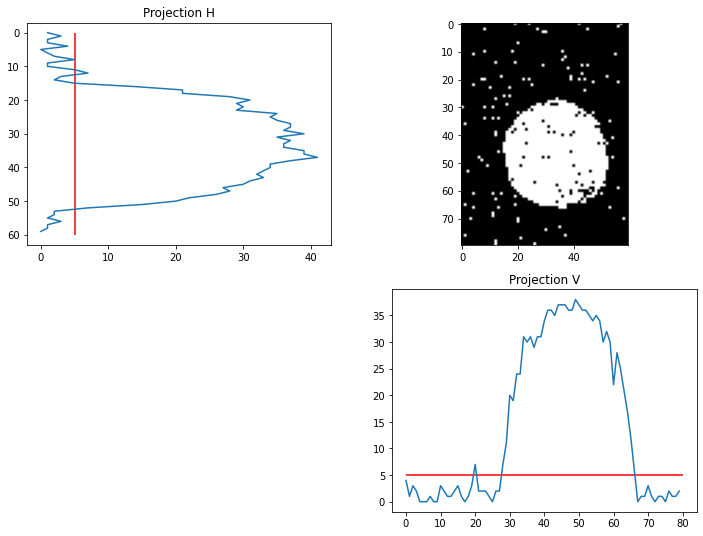

In [12]:
# read image
image = plt.imread('./data/coins.bmp')

# study shape
print('matrice dim : ', image.shape)
print('matrix min :',np.min(image))
print('matrix max :',np.max(image))
print('type matrice',type(image))
print('type pixel',type(image[0,0]))


# binariser
image_bin = image > 100

# projection on axis
proj_V = image_bin.sum(axis=0)
proj_H = image_bin.sum(axis=1)

# detect the border
T = 5
projbin_H = proj_H > T
projbin_V = proj_V > T


# find start and end of the object
idx_H_start = np.where(projbin_H)[0][0]
idx_H_end = np.where(projbin_H)[0][-1]

idx_V_start = np.where(projbin_V)[0][0]
idx_V_end = np.where(projbin_V)[0][-1]

# crop image
image_filt = image[idx_H_start:idx_H_end,idx_V_start:idx_V_end]


# display
plt.figure(figsize=(12,9))
ax= plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
plt.title('image')
ax = plt.subplot(1,3,2)
plt.imshow(image_bin, cmap='gray')
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
plt.title('image > T')
ax = plt.subplot(1,3,3)
plt.imshow(image_filt,cmap = 'gray')
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
plt.title('image crop')


plt.figure(figsize=(12,9))
ax = plt.subplot(2,2,1)
plt.plot(proj_V,np.arange(len(proj_V)))
plt.vlines(T,0,len(proj_V),'r')
plt.title('Projection H')
ax.invert_yaxis()
plt.subplot(2,2,2)
plt.imshow(image_bin, cmap='gray')
plt.subplot(2,2,4)
plt.plot(proj_H)
plt.hlines(T,0,len(proj_H),'r')
plt.title('Projection V')
#plt.plot(projbin_H*proj_H.max(),'r')
